# 1.Import Necessary libraries

In [54]:
import tensorflow as tf 
import keras
import matplotlib.pyplot as plt
import numpy as np

# 2.Import Data

In [55]:
(X_train, _), (X_test, _) = keras.datasets.mnist.load_data(path="mnist.npz")

In [56]:
X_train.shape,X_test.shape

((60000, 28, 28), (10000, 28, 28))

# 3.Data preparation

## 3.1 Add the chennal

In [57]:
X_train = X_train.reshape(60000,28,28,1)
X_test = X_test.reshape(10000,28,28,1)

In [58]:
X_train.shape,X_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

## 3.2 Normalize

In [59]:
X_train = X_train/255.0
X_test = X_test/255.0

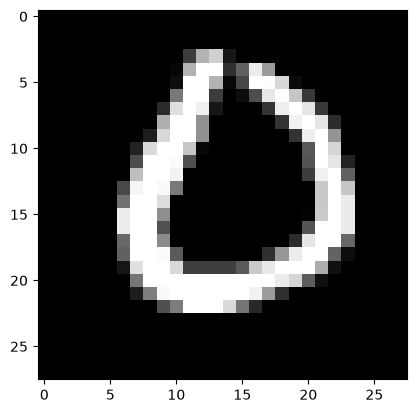

In [60]:
plt.imshow(X_train[2500],cmap='gray')

## 3.3 Add Noice

In [61]:
X_train_noise = X_train + 0.2 * np.random.normal(loc=0.0, scale=1.0, size=X_train.shape) #o.2 is given reasion for the value is high -5 so mul 0.2 value closer to 0 that reason can do this process
X_test_noise = X_test + 0.2 * np.random.normal(loc=0.0, scale=1.0, size=X_test.shape)

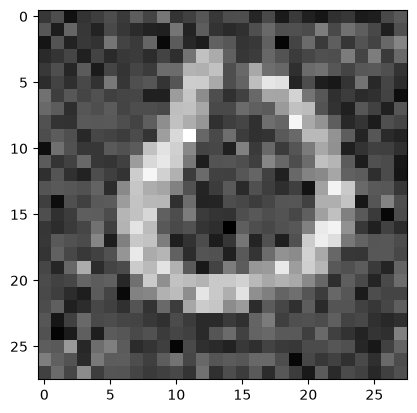

In [62]:
plt.imshow(X_train_noise[2500],cmap='gray')

In [63]:
X_train_noise.min(),X_train_noise.max()

(np.float64(-1.1255660779898207), np.float64(2.020990161237634))

## 3.4 Add Cliped

In [64]:
X_train_clipped = np.clip( a = X_train_noise,a_min=0,a_max=1) #I will have positive value only
X_test_clipped = np.clip( a = X_test_noise,a_min=0,a_max=1) # Clip use to change a all pixce value range for 0 to 1 are you can set the value

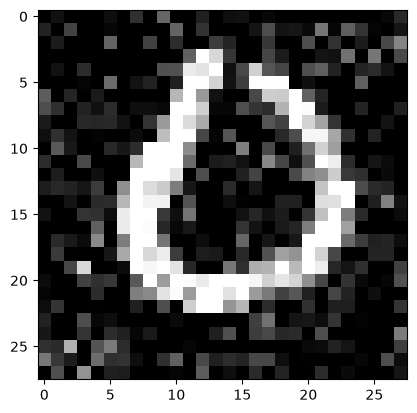

In [65]:
plt.imshow(X_train_clipped[2500],cmap='gray')

# 4.Model Building

In [66]:
from keras import Sequential
from keras.layers import Conv2D,MaxPool2D,UpSampling2D


import warnings
warnings.filterwarnings('ignore')

In [67]:
model = Sequential()

#Encoder - Compress the info
model.add(Conv2D( filters =32,kernel_size =(3,3),strides=(1, 1),padding='same',activation='relu',input_shape = (28,28,1)))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Conv2D( filters =8,kernel_size =(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(MaxPool2D(pool_size=(2,2)))

#Decoder - Expands
model.add(Conv2D( filters =8,kernel_size =(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(UpSampling2D(size=(2,2)))
model.add(Conv2D( filters =32,kernel_size =(3,3),strides=(1, 1),padding='same',activation='relu'))
model.add(UpSampling2D(size=(2,2)))
model.add(Conv2D( filters =1,kernel_size =(3,3),strides=(1, 1),padding='same',activation='relu'))

model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_29 (Conv2D)                   │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_18 (MaxPooling2D)      │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_30 (Conv2D)                   │ (None, 14, 14, 8)           │           2,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_19 (MaxPooling2D)      │ (None, 7, 7, 8)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_31 (Conv2D)                   │ (None, 7, 7, 8)             │             584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_5 (UpSampling2D)       │ (None, 14, 14, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_32 (Conv2D)                   │ (None, 14, 14, 32)          │           2,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_6 (UpSampling2D)       │ (None, 28, 28, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_33 (Conv2D)                   │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,841 (22.82 KB)

 Trainable params: 5,841 (22.82 KB)

 Non-trainable params: 0 (0.00 B)

# 5.Model Compilation

In [68]:
model.compile(optimizer='adam',loss='mean_squared_error',metrics=['accuracy'])

# 6.Model Training

In [69]:
model.fit( x=X_train_clipped,y=X_train,batch_size=32,epochs=5,validation_data=(X_test,X_test_clipped))#x,y this name is call slfe supperviced learning (input image as a output) own supervised input
# mean square error --> This is use for small error happen HIG PENALIZE the error pixcel to pixcel calculation    

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.8136 - loss: 0.0116 - val_accuracy: 0.4600 - val_loss: 0.0267
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8147 - loss: 0.0069 - val_accuracy: 0.4605 - val_loss: 0.0261
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8148 - loss: 0.0062 - val_accuracy: 0.4607 - val_loss: 0.0253
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8149 - loss: 0.0058 - val_accuracy: 0.4608 - val_loss: 0.0251
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8150 - loss: 0.0055 - val_accuracy: 0.4609 - val_loss: 0.0250


# 7.Model Evaluation

In [70]:
model.evaluate(X_test_clipped,X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8141 - loss: 0.0053


[0.005339023191481829, 0.8141047358512878]

# 8.Model Prediction

In [71]:
y_pred = model.predict(X_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


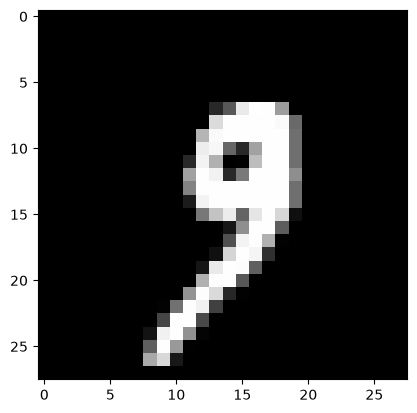

In [79]:
plt.imshow(X_test[1000],cmap='gray')

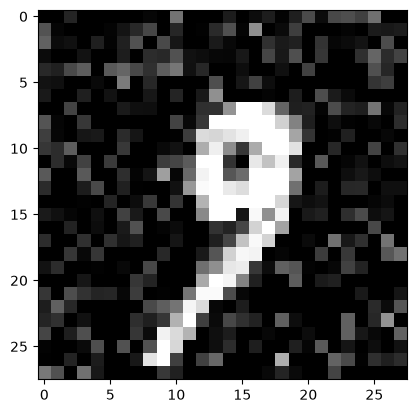

In [75]:
plt.imshow(X_test_clipped[1000],cmap='gray')

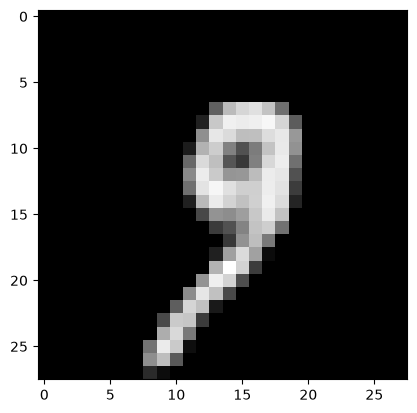

In [76]:
plt.imshow(y_pred[1000],cmap='gray')

# 9.Save the Model

In [80]:
model.save('denoising.h5')

# THE END !!!